<a href="https://colab.research.google.com/github/seanyi-creator/ba-305-project/blob/main/04_neural_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Team A7 - Predictive question (Neural Network)
**Question:** Can the details on a San Francisco building permit application predict whether the project will be abandoned rather than completed?

**Context:** Of the 62,148 resolved San Francisco building permits filed between 2000 and 2013, about 36% were never completed (expired, cancelled or withdrawn). Abandoned projects waste DBI review and inspection time. If the risk of abandonment can be estimated at filing, DBI can prioritize high-risk permits for early outreach.

**Why this model:** a neural network is a third way to capture non-linear patterns, learning smooth curves rather than yes/no rules. This notebook tunes the network; `06_model_comparison` tests whether it improves on the other models.

**Methodology:**
1. Use only the 23 features known at filing (loaded from `permits_data.py`), with a grouped 80/20 train/test split and grouped 5-fold cross-validation.
2. Test the effect of input scaling and watch the network overfit epoch by epoch.
3. Tune network size and weight decay (`alpha`), then learning rate and batch size, and check stability across random seeds.
4. Evaluate on ROC AUC, plus accuracy, recall and precision, against baselines.
5. Examine how well it flags the riskiest permits and which features drive it.

**Target:**
* `y = 1` if the permit did not finish (expired, cancelled, withdrawn, disapproved, revoked or denied)
* `y = 0` if completed
* Recall and precision therefore refer to failing permits.

In [1]:
# --- setup ---
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             RocCurveDisplay)
warnings.filterwarnings('ignore', category=ConvergenceWarning)   # explained in Step 3
pd.set_option('display.max_columns', 50)

## Shared data (from `permits_data.py`)
Same rows, features, grouped train/test split and preprocessor as the other models, so all results are comparable.

In [2]:
# --- shared data: cleaning code lives in permits_data.py ---
# In Colab the file isn't there yet, so download it from the team GitHub repo first.
import os, urllib.request
if not os.path.exists('permits_data.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/seanyi-creator/ba-305-project/main/permits_data.py',
        'permits_data.py')

from permits_data import get_permit_data, make_cv, make_preprocessor, NUMERIC, CATEGORICAL, RANDOM_STATE

In [3]:
# --- load the shared split ---
X_train, X_test, y_train, y_test, groups_train, preprocessor = get_permit_data()
cv = make_cv()
print(f'Train: {len(X_train):,} permits · Test: {len(X_test):,} permits · did not finish: {y_train.mean():.1%}')

Train: 49,676 permits · Test: 12,472 permits · did not finish: 35.7%


## Step 1 — Network design
| Choice | What we use | Why |
|---|---|---|
| Model | scikit-learn `MLPClassifier` | Plugs into the same `Pipeline`, grouped CV and `GridSearchCV` as the other models, so the comparison is like-for-like. |
| Hidden activation | ReLU | Standard default; trains faster than sigmoid or tanh. |
| Optimiser | Adam | Adapts the step size for each weight and works well with little tuning. |
| Inputs | the shared preprocessor (standardized numbers, one-hot categories) | Networks need inputs on similar scales (tested in Step 2). |
| Class imbalance | no reweighting | `MLPClassifier` has no `class_weight`. AUC does not depend on it, and the flagging cutoff is chosen separately (Step 9). |
| Score | ROC AUC with grouped 5-fold CV | Same metric as `02` and `03`. |

In [4]:
# --- Step 1 — what the network actually sees ---
Xt = make_preprocessor().fit_transform(X_train)
print(f'Each permit becomes {Xt.shape[1]} input numbers '
      f'({len(NUMERIC)} numeric features + missing-value flags + one-hot category columns).')
for h in [(32,), (64, 32)]:
    sizes = [Xt.shape[1], *h, 1]
    n_weights = sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))     # +1 = bias term
    print(f'A network with hidden layers {h} has {n_weights:,} weights to learn '
          f'(logistic regression has {Xt.shape[1] + 1}).')

Each permit becomes 166 input numbers (11 numeric features + missing-value flags + one-hot category columns).
A network with hidden layers (32,) has 5,377 weights to learn (logistic regression has 167).
A network with hidden layers (64, 32) has 12,801 weights to learn (logistic regression has 167).


**What this means:** logistic regression learns 167 numbers (one weight per input column plus an intercept). Even a small network with one hidden layer of 32 neurons learns **5,377**, and a two-layer one more than 12,000. That extra capacity is what lets a network find curved patterns and interactions, and it is also what lets it **memorise** the training permits. Most of this notebook is about using that capacity without overfitting.

## Step 2 — Input scaling
Before training, every weight starts small and gets nudged by the same size of step. If one input runs from 2000 to 2013 (`filing_year`) and another is 0 or 1 (a one-hot column), a single step size can't suit both: the big-valued input swamps the others, and training is slow and unstable. Standardizing (mean 0, standard deviation 1) puts every numeric input on the same footing.

Trees don't care about scale (they only compare a value with a threshold), so this mattered for logistic regression but not for `03`. For a network it matters a lot. The experiment below trains the same small network with and without scaling.

In [5]:
# --- Step 2 — same network, with and without standardized inputs ---
def make_unscaled_preprocessor():
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True))])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='missing')),
                            ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50))])
    return ColumnTransformer([('num', numeric, NUMERIC), ('cat', categorical, CATEGORICAL)])

def mlp(**kw):
    """The network used throughout: ReLU + Adam, early stopping on, fixed seed."""
    params = dict(hidden_layer_sizes=(32,), early_stopping=True, n_iter_no_change=10, max_iter=300,
                  random_state=RANDOM_STATE)
    params.update(kw)
    return MLPClassifier(**params)

rows = []
for name, prep in [('standardized (shared preprocessor)', make_preprocessor()),
                   ('raw numbers (no scaling)', make_unscaled_preprocessor())]:
    r = cross_validate(Pipeline([('prep', prep), ('model', mlp())]), X_train, y_train,
                       groups=groups_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    rows.append({'inputs': name, 'CV AUC': r['test_score'].mean(), 'CV AUC (sd)': r['test_score'].std()})
pd.DataFrame(rows).set_index('inputs').round(4)

,CV AUC,CV AUC (sd)
inputs,,
standardized (shared preprocessor),0.6624,0.0077
raw numbers (no scaling),0.6027,0.0096


**Result:** the identical network scores **0.662** CV AUC with standardized inputs and only **0.603** on raw numbers, a drop of 0.06. On raw numbers, `filing_year` (≈ 2000–2013) and `log_estimated_cost` (≈ 2–9) dwarf the 0/1 columns, and training never settles properly.

**Design choice:** keep the shared preprocessor's standardization. It is also why this notebook can reuse the shared cell unchanged.

## Step 3 — Training
To see overfitting happen, we train a fairly large network (128 neurons) **one epoch at a time** with almost no regularization. After each epoch we score it on its own training permits and on a held-out validation fold (one grouped fold from the training set; the test set is still untouched).

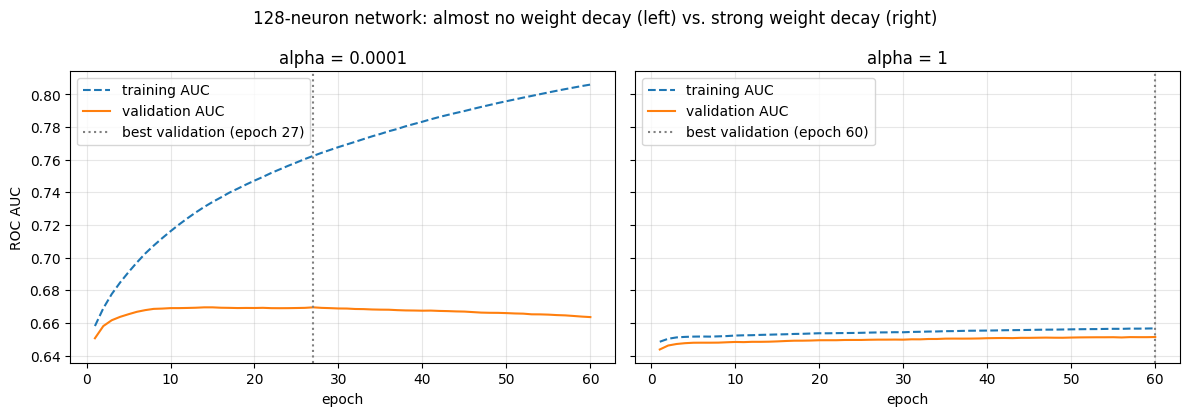

,alpha = 0.0001,alpha = 1
best validation AUC,0.6696,0.6514
at epoch,27.0000,60.0000
validation AUC after 60 epochs,0.6636,0.6514
training AUC after 60 epochs,0.8060,0.6567


In [6]:
# --- Step 3 — training vs validation AUC after every epoch ---
fit_idx, val_idx = next(cv.split(X_train, y_train, groups_train))
prep3 = make_preprocessor().fit(X_train.iloc[fit_idx])
Xf, Xv = prep3.transform(X_train.iloc[fit_idx]), prep3.transform(X_train.iloc[val_idx])
yf, yv = y_train.iloc[fit_idx].to_numpy(), y_train.iloc[val_idx].to_numpy()

def epoch_curve(alpha, epochs=60, hidden=(128,)):
    net = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, random_state=RANDOM_STATE)
    tr, va = [], []
    for _ in range(epochs):
        net.partial_fit(Xf, yf, classes=[0, 1])                 # one more pass over the data
        tr.append(roc_auc_score(yf, net.predict_proba(Xf)[:, 1]))
        va.append(roc_auc_score(yv, net.predict_proba(Xv)[:, 1]))
    return np.array(tr), np.array(va)

curves = {a: epoch_curve(a) for a in [1e-4, 1.0]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (a, (tr, va)) in zip(axes, curves.items()):
    ep = np.arange(1, len(tr) + 1)
    ax.plot(ep, tr, '--', label='training AUC'); ax.plot(ep, va, label='validation AUC')
    ax.axvline(ep[va.argmax()], color='grey', ls=':', label=f'best validation (epoch {ep[va.argmax()]})')
    ax.set_title(f'alpha = {a:g}'); ax.set_xlabel('epoch'); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel('ROC AUC')
fig.suptitle('128-neuron network: almost no weight decay (left) vs. strong weight decay (right)')
plt.tight_layout(); plt.show()
pd.DataFrame({f'alpha = {a:g}': {'best validation AUC': va.max(), 'at epoch': int(va.argmax()) + 1,
                                  'validation AUC after 60 epochs': va[-1], 'training AUC after 60 epochs': tr[-1]}
              for a, (tr, va) in curves.items()}).round(4)

**Reading the curves:**
- **Left (alpha = 0.0001, almost no penalty):** validation AUC climbs fast and peaks at **0.670 around epoch 15–27**, then slowly *falls* (0.664 by epoch 60), while training AUC keeps climbing to 0.806. That widening gap is **overfitting in real time**: after about 20 epochs the extra training only memorises noise.
- **Right (alpha = 1, strong penalty):** training and validation stay glued together, but both are stuck around 0.65. The penalty is so strong the network can't learn the patterns it needs: **underfitting**.

**Takeaways that shape the rest of the notebook:**
1. **Stop training at the right epoch** (early stopping), because the best validation score comes long before the network stops improving on training data.
2. **Tune `alpha`** to sit between the two extremes.

## Step 4 — Regularization
Step 3 shows the two tools that keep a network honest. Both are used from here on.

**1. Weight decay (`alpha`)** adds a penalty for large weights to the loss, exactly like `C` in logistic regression but the other way round: **larger `alpha` = stronger penalty = simpler network**. It is tuned in Step 5.

**2. Early stopping:** set aside 10% of the training rows inside each fit, check them after every epoch, and stop once they haven't improved for 10 epochs in a row (`n_iter_no_change=10`). The network keeps the weights from its best epoch. This picks the number of epochs automatically, so it doesn't need to be tuned.

**Why early stopping is on, and its small cost.** Without it, each network would train for a fixed number of epochs (too few: underfit; too many: overfit, as Step 3 shows), which would be one more hyperparameter to search. The cost: scikit-learn's internal 10% is a *random* sample of rows (not grouped by project batch) and it watches accuracy, not AUC. That makes the stopping point slightly noisy, but the hyperparameters are still *chosen* by grouped-CV AUC, so the comparison with other models stays fair.

*(The `ConvergenceWarning` silenced in the setup cell is scikit-learn saying a network hit `max_iter` before early stopping fired. With early stopping on, that rarely happens and is harmless.)*

## Step 5 — Hyperparameter tuning (network size, weight decay)
These two hyperparameters set how complex the network can be, so they are tuned together:
- **`hidden_layer_sizes`**: the architecture. One hidden layer of 16, 32, 64 or 128 neurons, or two layers (32→16, 64→32). More neurons and layers mean more capacity to learn patterns, and more room to memorise noise.
- **`alpha`**: weight decay from 0.0001 (almost none) to 1 (strong), on a log scale, because its effect works in multiples.

6 architectures × 5 alphas = **30 combinations**, each scored by ROC AUC with grouped 5-fold CV on the training set. Everything else stays at the defaults from Step 2 (Adam, learning rate 0.001, batches of 200).

**Why a grid in two rounds, not everything at once?** A network has many knobs. Searching all of them together multiplies the combinations (6 × 5 × 4 × 2 = 240 × 5 folds), so we tune the knobs that control *complexity* first, then the knobs that control *how training moves* (round 2).

In [7]:
# --- Step 5 — round 1: architecture × alpha ---
def nn_pipe(**kw):
    return Pipeline([('prep', make_preprocessor()), ('model', mlp(**kw))])

grid1 = {'model__hidden_layer_sizes': [(16,), (32,), (64,), (128,), (32, 16), (64, 32)],
         'model__alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1.0]}
t0 = time.time()
search1 = GridSearchCV(nn_pipe(), grid1, cv=cv, scoring='roc_auc', return_train_score=True, n_jobs=-1)
search1.fit(X_train, y_train, groups=groups_train)
res1 = pd.DataFrame(search1.cv_results_)
res1['architecture'] = res1['param_model__hidden_layer_sizes'].astype(str)
print(f'{len(res1)} combinations × 5 folds in {time.time() - t0:.0f}s')
print('Best:', search1.best_params_, '· CV AUC', round(search1.best_score_, 4))
order = [str(h) for h in grid1['model__hidden_layer_sizes']]
(res1.pivot_table(index='architecture', columns='param_model__alpha', values='mean_test_score')
     .loc[order].round(4).rename_axis(index='hidden layers', columns='alpha → (CV AUC)'))

30 combinations × 5 folds in 529s
Best: {'model__alpha': 0.1, 'model__hidden_layer_sizes': (64,)} · CV AUC 0.6657


alpha → (CV AUC),0.0001,0.0010,0.0100,0.1000,1.0000
hidden layers,,,,,
"(16,)",0.6570,0.6588,0.6599,0.6625,0.6485
"(32,)",0.6624,0.6618,0.6632,0.6618,0.6493
"(64,)",0.6610,0.6613,0.6611,0.6657,0.6476
"(128,)",0.6617,0.6612,0.6639,0.6656,0.6482
"(32, 16)",0.6610,0.6633,0.6618,0.6633,0.6505
"(64, 32)",0.6542,0.6595,0.6588,0.6630,0.6495


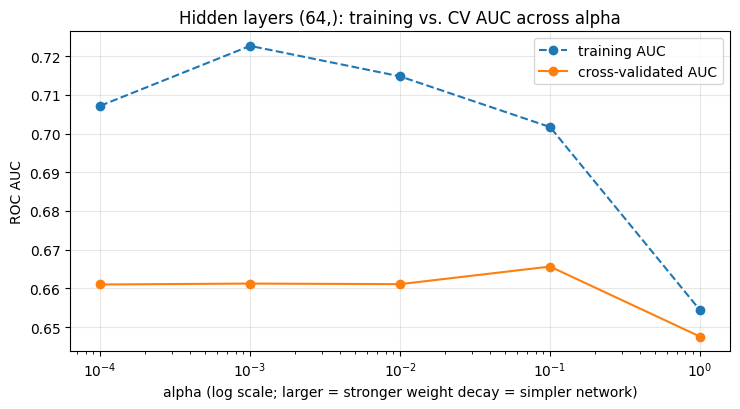

,training AUC,CV AUC,CV AUC (sd)
alpha,,,
0.0001,0.7071,0.6610,0.0030
0.0010,0.7226,0.6613,0.0043
0.0100,0.7148,0.6611,0.0031
0.1000,0.7017,0.6657,0.0051
1.0000,0.6544,0.6476,0.0052


In [8]:
# --- Step 5 — over/underfitting across alpha for the best architecture ---
best_arch = search1.best_params_['model__hidden_layer_sizes']
sub = res1[res1['architecture'] == str(best_arch)].sort_values('param_model__alpha')
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(sub['param_model__alpha'].astype(float), sub['mean_train_score'], '--o', label='training AUC')
ax.plot(sub['param_model__alpha'].astype(float), sub['mean_test_score'], '-o', label='cross-validated AUC')
ax.set_xscale('log'); ax.set_xlabel('alpha (log scale; larger = stronger weight decay = simpler network)')
ax.set_ylabel('ROC AUC'); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f'Hidden layers {best_arch}: training vs. CV AUC across alpha')
plt.tight_layout(); plt.show()
sub[['param_model__alpha', 'mean_train_score', 'mean_test_score', 'std_test_score']].round(4) \
    .set_axis(['alpha', 'training AUC', 'CV AUC', 'CV AUC (sd)'], axis=1).set_index('alpha')

**Reading round 1:**
- **Best: one hidden layer of 64 neurons with `alpha = 0.1`, CV AUC 0.666.** (128 neurons at `alpha = 0.1` ties at 0.6656. 64 is kept because it is smaller and does the same job.)
- **`alpha` matters more than the architecture.** Down each column the scores barely move (≈ 0.66), but `alpha = 1` drags every architecture down to ≈ 0.65 (underfitting, as in Step 3).
- **The best value is inside the range,** not at an edge: `alpha = 1` is clearly worse and 0.0001–0.01 slightly worse, so the range was wide enough.
- **Bigger isn't better.** The largest network (64 → 32) is the weakest at low `alpha` (0.654): more weights, more memorising. A second layer adds nothing here.
- **The fit curve:** training AUC sits at 0.70–0.72 for small `alpha` against a CV AUC of 0.661, a gap of about 0.05, which is mild overfitting. At `alpha = 0.1` the gap narrows (0.702 vs. 0.666) and CV is highest. At `alpha = 1` the gap closes, but both scores drop (0.654 vs. 0.648): underfitting.

**Why one hidden layer is enough:** with 23 original features, most of the signal is a handful of strong effects (filing year, cost, size) with some bends and interactions. One layer of neurons can already represent any smooth curve of the inputs, and extra depth pays off mainly on raw data such as images or text, where features must be built up in stages.

## Step 6 — Hyperparameter tuning (learning rate, batch size)
With the size and the penalty fixed at their round-1 best, we tune how training *moves*:
- **`learning_rate_init`**: the size of each step downhill. Too small and training crawls (early stopping may cut it off before it gets anywhere); too large and it overshoots and bounces around. Tried 0.0003, 0.001 (default), 0.003 and 0.01.
- **`batch_size`**: how many permits are used for each step. Small batches (64) mean many noisy steps per epoch, and the noise can help escape poor solutions. Large batches (256) mean fewer, smoother steps.

4 × 2 = **8 combinations**, same grouped 5-fold CV.

In [9]:
# --- Step 6 — round 2: learning rate × batch size at the round-1 best ---
best_alpha = search1.best_params_['model__alpha']
grid2 = {'model__learning_rate_init': [3e-4, 1e-3, 3e-3, 1e-2], 'model__batch_size': [64, 256]}
t0 = time.time()
search2 = GridSearchCV(nn_pipe(hidden_layer_sizes=best_arch, alpha=best_alpha), grid2, cv=cv,
                       scoring='roc_auc', return_train_score=True, n_jobs=-1)
search2.fit(X_train, y_train, groups=groups_train)
res2 = pd.DataFrame(search2.cv_results_)
NN_BEST = {'hidden_layer_sizes': best_arch, 'alpha': best_alpha,
           'learning_rate_init': search2.best_params_['model__learning_rate_init'],
           'batch_size': search2.best_params_['model__batch_size']}
print(f'{len(res2)} combinations × 5 folds in {time.time() - t0:.0f}s')
print('NN_BEST =', NN_BEST, '· CV AUC', round(search2.best_score_, 4))
(res2.pivot_table(index='param_model__learning_rate_init', columns='param_model__batch_size', values='mean_test_score')
     .round(4).rename_axis(index='learning rate', columns='batch size → (CV AUC)'))

8 combinations × 5 folds in 101s
NN_BEST = {'hidden_layer_sizes': (64,), 'alpha': 0.1, 'learning_rate_init': 0.001, 'batch_size': 256} · CV AUC 0.6657


batch size → (CV AUC),64,256
learning rate,,
0.0003,0.6627,0.6633
0.0010,0.6628,0.6657
0.0030,0.6554,0.6646
0.0100,0.6441,0.6608


**Reading round 2:**
- **Best: learning rate 0.001 with batches of 256, CV AUC 0.666,** essentially the defaults (0.001 and 200). Adam's defaults are well chosen, which is one reason we picked Adam.
- **Too large a learning rate hurts,** especially with small batches: 0.01 with batches of 64 drops to 0.644, because many big, noisy steps overshoot. Larger batches smooth each step, so they tolerate faster rates better.
- **Too small a rate is fine but not better** (0.663): training just takes more epochs to get to the same place.

**Final settings, `NN_BEST`:** one hidden layer of 64 ReLU neurons, `alpha = 0.1`, learning rate 0.001, batches of 256, Adam, with early stopping.

## Step 7 — Seed stability
A network starts from random weights, and early stopping draws a random 10% of rows, so two runs with different seeds give slightly different networks. To check how much this matters, we refit the tuned settings with 5 different seeds and look at the spread of CV AUC.

**Why it matters:** if the spread were large, a single run's score could not be trusted.

In [10]:
# --- Step 7 — same settings, five random seeds ---
rows = []
for seed in [0, 1, 2, 3, 42]:
    r = cross_validate(nn_pipe(**NN_BEST, random_state=seed), X_train, y_train, groups=groups_train,
                       cv=cv, scoring='roc_auc', n_jobs=-1)
    rows.append({'seed': seed, 'CV AUC': r['test_score'].mean()})
seeds = pd.DataFrame(rows).set_index('seed')
print(f"CV AUC across seeds: mean {seeds['CV AUC'].mean():.4f}, "
      f"range {seeds['CV AUC'].min():.4f}–{seeds['CV AUC'].max():.4f}")
seeds.round(4).T

CV AUC across seeds: mean 0.6661, range 0.6644–0.6674


seed,0,1,2,3,42
CV AUC,0.6674,0.6662,0.6667,0.6644,0.6657


**Result:** across five seeds the CV AUC ranges from **0.664 to 0.667** (mean 0.666), a spread of only 0.003. The network is **stable**: a different random start would barely change its score. One seed (42) is used from here on.

## Step 8 — Model evaluation
The tuned network (`NN_BEST`) is refitted on all training permits and scored **once** on the test set, against the two baselines. The comparison with the other models is in `06_model_comparison`.

In [11]:
# --- Step 8 — fit the tuned network on the training set, score once on the test set ---
nn_final = nn_pipe(**NN_BEST)
t0 = time.time(); nn_final.fit(X_train, y_train); secs = time.time() - t0
prob_nn = nn_final.predict_proba(X_test)[:, 1]

def scores(prob, pred):
    return {'test ROC AUC': roc_auc_score(y_test, prob), 'accuracy': accuracy_score(y_test, pred),
            'error rate': 1 - accuracy_score(y_test, pred), 'recall': recall_score(y_test, pred, zero_division=0),
            'precision': precision_score(y_test, pred, zero_division=0),
            'F1': f1_score(y_test, pred, zero_division=0), 'share flagged': pred.mean()}

rows = []
for name, strategy in [('Baseline: always "completed"', 'most_frequent'), ('Baseline: random guess', 'stratified')]:
    d = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE).fit(X_train, y_train)
    rows.append({'model': name, **scores(d.predict_proba(X_test)[:, 1], d.predict(X_test))})
rows.append({'model': 'Neural network', **scores(prob_nn, (prob_nn >= 0.5).astype(int))})
results = pd.DataFrame(rows).set_index('model').round(3)
print(f'Neural network: CV AUC {search2.best_score_:.3f} → test AUC {results.loc["Neural network", "test ROC AUC"]:.3f} '
      f'· fitted in {secs:.1f}s')
results

Neural network: CV AUC 0.666 → test AUC 0.659 · fitted in 3.4s


,test ROC AUC,accuracy,error rate,recall,precision,F1,share flagged
model,,,,,,,
"Baseline: always ""completed""",0.500,0.633,0.367,0.000,0.000,0.000,0.000
Baseline: random guess,0.498,0.538,0.462,0.349,0.365,0.357,0.351
Neural network,0.659,0.648,0.352,0.303,0.538,0.387,0.207


**Reading the table:**
- **Test AUC 0.659**, against 0.50 for both baselines.
- **CV and test agree** (0.666 → 0.659), so the tuning carried over to unseen permits.
- **At the 0.5 cutoff** the network flags 21% of permits, and 54% of those really fail, against a 37% base rate. Accuracy (64.8%) is only 1.5 points above always predicting "completed" (63.3%), which catches no failures at all.

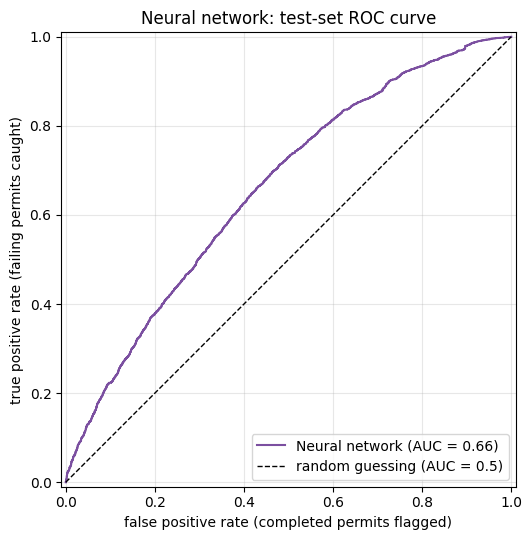

In [12]:
# --- Step 8 — ROC curve ---
fig, ax = plt.subplots(figsize=(6, 5.5))
RocCurveDisplay.from_predictions(y_test, prob_nn, name='Neural network', ax=ax, color='#7b4fa0')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='random guessing (AUC = 0.5)')
ax.set_xlabel('false positive rate (completed permits flagged)')
ax.set_ylabel('true positive rate (failing permits caught)')
ax.set_title('Neural network: test-set ROC curve'); ax.legend(loc='lower right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Step 9 — Risk ranking
If staff can follow up on the riskiest k% of new permits, how many of those really fail?

In [13]:
# --- Step 9 — review the riskiest k% of test permits ---
rows = []
for k in [0.05, 0.10, 0.20, 0.30]:
    flag = (prob_nn >= np.quantile(prob_nn, 1 - k)).astype(int)
    rows.append({'review the riskiest': f'{k:.0%}', 'precision': precision_score(y_test, flag),
                 'recall': recall_score(y_test, flag)})
print(f'Base rate (share of test permits that did not finish): {y_test.mean():.1%}')
pd.DataFrame(rows).set_index('review the riskiest').round(3)

Base rate (share of test permits that did not finish): 36.7%


,precision,recall
review the riskiest,,
5%,0.630,0.086
10%,0.588,0.160
20%,0.539,0.293
30%,0.511,0.418


**Reading the table:** reviewing the riskiest 10% of permits, **59%** of the network's picks really fail (1.6× the 37% base rate) and 16% of all failures are caught. Larger lists catch more failures at lower precision: at 30%, precision is 51% and recall 42%.

## Step 10 — Feature importance
Permutation importance: shuffle one feature in the test set and measure the drop in AUC.

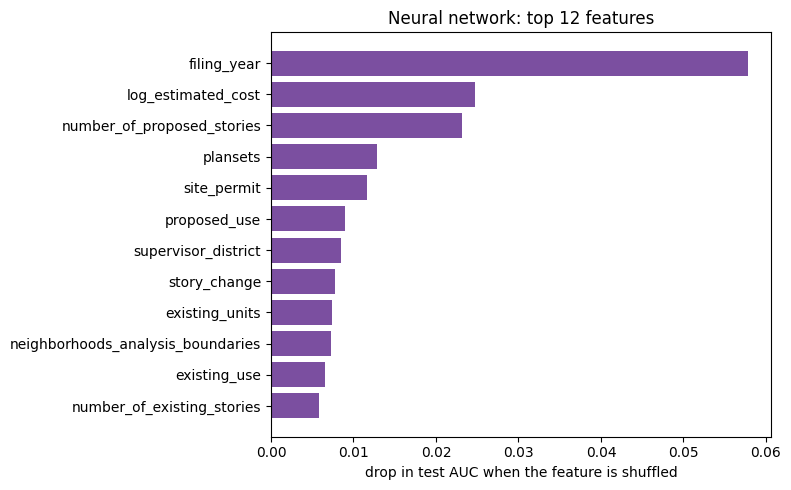

,AUC drop
filing_year,0.0578
log_estimated_cost,0.0247
number_of_proposed_stories,0.0232
plansets,0.0129
site_permit,0.0117
proposed_use,0.0090
supervisor_district,0.0085
story_change,0.0078
existing_units,0.0074
neighborhoods_analysis_boundaries,0.0073


In [14]:
# --- Step 10 — permutation importance ---
r = permutation_importance(nn_final, X_test, y_test, scoring='roc_auc', n_repeats=5,
                           random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top, color='#7b4fa0')
ax.set_xlabel('drop in test AUC when the feature is shuffled')
ax.set_title('Neural network: top 12 features')
plt.tight_layout(); plt.show()
imp.round(4).to_frame('AUC drop')

**Reading the chart:** `filing_year` matters most by a wide margin (AUC drop 0.058), followed by estimated cost (0.025) and proposed stories (0.023). Plan sets, site permits, proposed use and location come next. The reliance on filing year means much of the signal is "when was it filed", which won't transfer cleanly to permits filed today.

## Step 11 — Conclusions
### What we found
1. **The tuned network (one hidden layer of 64 neurons, `alpha = 0.1`) reaches a test AUC of 0.659**, well above the 0.50 baselines, with CV and test in agreement.
2. **Its riskiest 10% of permits fail at 59%,** against a 37% base rate.
3. **Filing year, cost and building size drive its predictions.**

How it compares with logistic regression, the tree and the forest is in `06_model_comparison`.

### Design choices recap

| Choice | Decision | Evidence in this notebook |
|---|---|---|
| Input scaling | Standardize | Without it, CV AUC drops from 0.662 to 0.603 (Step 2) |
| Depth | One hidden layer | Two layers never beat one; the largest network was the worst (Step 5) |
| Width | 64 neurons | Ties with 128; the smaller network is preferred |
| Weight decay | `alpha = 0.1` | Inside the tested range: less overfits, `1.0` underfits (Steps 3 and 5) |
| Training length | Early stopping (patience 10) | Validation AUC peaks long before training AUC stops rising (Step 3) |
| Optimiser and learning rate | Adam, 0.001, batches of 256 | Defaults were best; fast rates with small batches hurt (Step 6) |
| Random seed | Fixed at 42 | Seed spread is 0.003 AUC (Step 7) |
| Class imbalance | No reweighting | AUC is unaffected; staff capacity sets the cutoff (Step 9) |

### Limitations
- **Filing year** carries much of the signal (Step 10).
- **Early stopping** uses scikit-learn's random 10% of rows, not grouped batches, so the stopping point is slightly noisy.
- **Grid search** covers the main hyperparameters but not every option, for example dropout or batch normalisation, which `MLPClassifier` doesn't offer.